# Initial Model Archictecture (VinBigData only)

In [16]:
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import os
os.environ["TF_GPU_ALLOCATOR"] = "cuda_malloc_async"
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.densenet import preprocess_input
from keras.models import Sequential
from keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import metrics
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.initializers import Constant

# GPU setup: allocate GPU memory as needed, and use mixed precision (float16 compute) to fit the 4 GB card
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
if gpus:
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
print("GPUs:", gpus)

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [17]:
def load_data(path):
    data = []
    filenames = []
    for img_name in os.listdir(path):
        try:
            if img_name.endswith(".png"):
                img_path = os.path.join(path, img_name)
                img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
                if img.ndim == 2: # Convert grayscale to 3 channels (BGR)
                    img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
                data.append(img)
                filenames.append(img_name)
            else:
                print(f"Skipping file: {img_name}")
        except Exception as e:
            print(f"Error loading image {img_name}: {e}")
            continue
    return data, filenames

In [18]:
from sklearn.model_selection import train_test_split


# use the copy in the WSL filesystem when it exists (much faster to read than /mnt/c)
WSL_DATA = os.path.expanduser("~/GeneralizedCXR/data")
DATA_DIR = WSL_DATA if os.path.isdir(WSL_DATA) else "../data"
print("Data from:", DATA_DIR)

IMGDIR = os.path.join(DATA_DIR, "vinbigdata_images")
test = pd.read_csv(os.path.join(DATA_DIR, "vinbigdata_labels_TEST.csv"))
train = pd.read_csv(os.path.join(DATA_DIR, "vinbigdata_labels_TRAIN.csv"))
data, filenames = load_data(IMGDIR)
print(f"Loaded {len(data)} images")
images = dict(zip(filenames, data))
test_imgs = np.array([images[img_name + ".png"] for img_name in test['image_id']])
train_imgs = np.array([images[img_name + ".png"] for img_name in train['image_id']])
del data, images
train_labels = train['label'].astype(int).values
test_labels = test['label'].astype(int).values

train_imgs, val_imgs, train_labels, val_labels = train_test_split(
    train_imgs, train_labels, test_size=0.2, stratify=train_labels, random_state=10)

Data from: /home/power/GeneralizedCXR/data
Loaded 15000 images


In [19]:
print(train_imgs.shape)
print(train_labels.shape)

print(val_imgs.shape)
print(val_labels.shape)

print(test_imgs.shape)
print(test_labels.shape)

(10400, 224, 224, 3)
(10400,)
(2600, 224, 224, 3)
(2600,)
(2000, 224, 224, 3)
(2000,)


In [20]:
# same DenseNet preprocessing for train, val and test (augmentation on training batches only)
datagen = ImageDataGenerator(brightness_range=[0.8, 1.2], preprocessing_function=preprocess_input)
# val/test are preprocessed batch by batch, in order, so no float32 copy of the whole array is kept in memory
evalgen = ImageDataGenerator(preprocessing_function=preprocess_input)

In [21]:
tf.keras.backend.clear_session()

pretrained = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

p = train_labels.mean()  # training prevalence

model = Sequential([
    pretrained,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    # float32 output keeps the probabilities numerically stable under mixed precision
    Dense(1, activation='sigmoid', dtype='float32',
          bias_initializer=Constant(np.log(p / (1 - p))))
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,103,169 (27.10 MB)

 Trainable params: 7,019,521 (26.78 MB)

 Non-trainable params: 83,648 (326.75 KB)

In [22]:
BATCH = 8
EPOCHS = 10

model.compile(optimizer=Adam(learning_rate=1e-4, gradient_accumulation_steps=4), 
              loss='binary_crossentropy', 
              metrics=[metrics.AUC(name="auroc"), metrics.AUC(curve="PR", name="auprc")],
              jit_compile=False)
model_history = model.fit(
    datagen.flow(train_imgs, train_labels, batch_size=BATCH),
    epochs=EPOCHS, verbose=1, validation_data=evalgen.flow(val_imgs, val_labels, batch_size=BATCH, shuffle=False),
    callbacks=[EarlyStopping(monitor='val_auroc', mode='max', patience=3, restore_best_weights=True),
               ModelCheckpoint('best_model.keras', monitor='val_auroc', mode='max', save_best_only=True)])

Epoch 1/10
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 2293s 2s/step - auprc: 0.4845 - auroc: 0.8683 - loss: 0.1748 - val_auprc: 0.7301 - val_auroc: 0.9601 - val_loss: 0.1211
Epoch 2/10
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 2158s 2s/step - auprc: 0.7663 - auroc: 0.9570 - loss: 0.1071 - val_auprc: 0.7471 - val_auroc: 0.9560 - val_loss: 0.1114
Epoch 3/10
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 4262s 3s/step - auprc: 0.8478 - auroc: 0.9735 - loss: 0.0830 - val_auprc: 0.8159 - val_auroc: 0.9659 - val_loss: 0.0957
Epoch 4/10
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 14916s 11s/step - auprc: 0.8885 - auroc: 0.9820 - loss: 0.0681 - val_auprc: 0.7954 - val_auroc: 0.9578 - val_loss: 0.1056
Epoch 5/10
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 2389s 2s/step - auprc: 0.9317 - auroc: 0.9884 - loss: 0.0514 - val_auprc: 0.7785 - val_auroc: 0.9516 - val_loss: 0.1134
Epoch 6/10
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 2205s 2s/step - auprc: 0.9626 - auroc: 0.9944 - loss: 0.0367 - val_auprc: 0.7355 - val_auroc: 0.9045 - val_loss: 0.1660


In [23]:
from keras.models import load_model
model = load_model('best_model.keras')

In [24]:
model_score = model.evaluate(evalgen.flow(val_imgs, val_labels, batch_size=BATCH, shuffle=False), return_dict=True)
print("\nValidation AUROC:", round(model_score["auroc"], 3))
print("Validation AUPRC:", round(model_score["auprc"], 3), f"(prevalence {val_labels.mean():.3f})")
print("Validation loss:", round(model_score["loss"], 4))

148/325 ━━━━━━━━━━━━━━━━━━━━ 45s 259ms/step - auprc: 0.8391 - auroc: 0.9692 - loss: 0.0943

325/325 ━━━━━━━━━━━━━━━━━━━━ 92s 265ms/step - auprc: 0.8159 - auroc: 0.9659 - loss: 0.0957

Validation AUROC: 0.966
Validation AUPRC: 0.816 (prevalence 0.069)
Validation loss: 0.0957


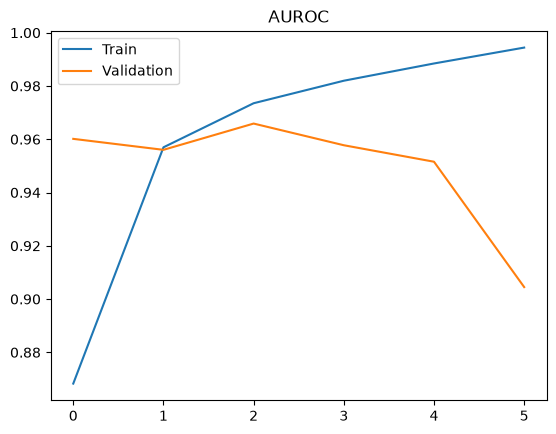

In [25]:
fig, axes = plt.subplots(1, 1)
axes.plot(model_history.history['auroc'], label='Train')
axes.plot(model_history.history['val_auroc'], label='Validation')
axes.set_title('AUROC')
axes.legend()

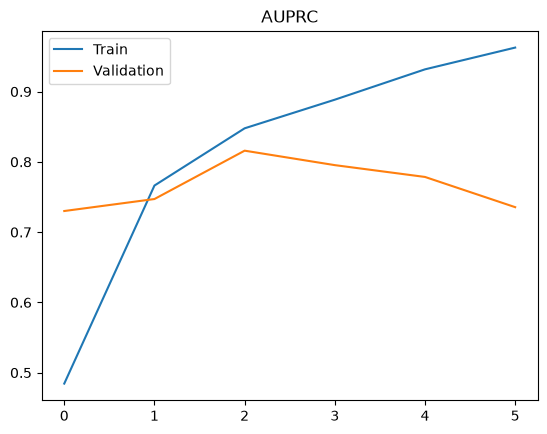

In [26]:
fig, axes = plt.subplots(1, 1)
axes.plot(model_history.history['auprc'], label='Train')
axes.plot(model_history.history['val_auprc'], label='Validation')
axes.set_title('AUPRC')
axes.legend()

 20/325 ━━━━━━━━━━━━━━━━━━━━ 1:17 253ms/step

325/325 ━━━━━━━━━━━━━━━━━━━━ 85s 249ms/step
Threshold: 0.073
Confusion Matrix:
[[2281  140]
 [  23  156]]


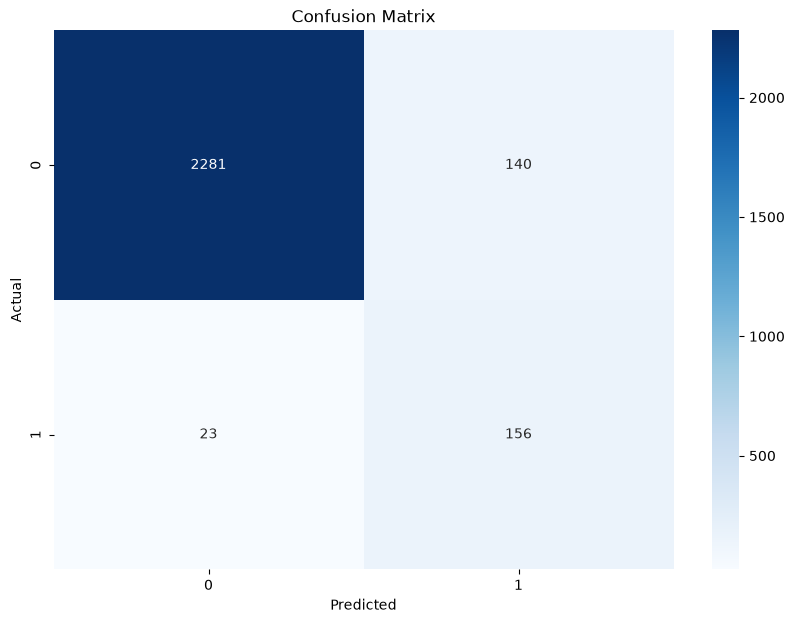

In [27]:
# confusion matrix at a threshold chosen on the validation set (Youden's J), not 0.5
from sklearn.metrics import confusion_matrix, roc_curve
import seaborn as sns

y_prob = model.predict(evalgen.flow(val_imgs, batch_size=BATCH, shuffle=False))[:, 0]
fpr, tpr, thresholds = roc_curve(val_labels, y_prob)
threshold = thresholds[np.argmax(tpr - fpr)]
y_pred_classes = (y_prob >= threshold).astype(int)
cm = confusion_matrix(val_labels, y_pred_classes)
print(f"Threshold: {threshold:.3f}")
print("Confusion Matrix:")
print(cm)

# plot confusion matrix
plt.figure(figsize=(10,7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [28]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.special import logit, expit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             confusion_matrix, brier_score_loss)


def choose_threshold(y_true, y_prob):
    """Youden's J threshold, chosen on the validation set only."""
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    return thr[np.argmax(tpr - fpr)]


def calibration_intercept_slope(y_true, y_prob):
    """Calibration-in-the-large (intercept with slope fixed at 1) and calibration slope.
    Ideal: intercept 0, slope 1."""
    lp = logit(np.clip(y_prob, 1e-7, 1 - 1e-7)).reshape(-1, 1)
    slope = LogisticRegression(penalty=None).fit(lp, y_true).coef_[0, 0]
    # intercept a in logit(P(y=1)) = a + lp, i.e. lp used as an offset
    nll = lambda a: -np.mean(y_true * np.log(expit(a + lp[:, 0]))
                             + (1 - y_true) * np.log(1 - expit(a + lp[:, 0])))
    intercept = minimize_scalar(nll).x
    return intercept, slope


def expected_calibration_error(y_true, y_prob, n_bins=10):
    """ECE with equal-count (quantile) bins, which suits low prevalence."""
    bins = np.quantile(y_prob, np.linspace(0, 1, n_bins + 1))
    idx = np.clip(np.digitize(y_prob, bins[1:-1]), 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y_prob[m].mean() - y_true[m].mean())
    return ece


def compute_metrics(y_true, y_prob, threshold):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if tp + fn else np.nan
    spec = tn / (tn + fp) if tn + fp else np.nan
    ppv = tp / (tp + fp) if tp + fp else np.nan
    npv = tn / (tn + fn) if tn + fn else np.nan
    intercept, slope = calibration_intercept_slope(y_true, y_prob)
    return {
        "AUROC": roc_auc_score(y_true, y_prob),
        "AUPRC": average_precision_score(y_true, y_prob),
        "Sensitivity": sens,
        "Specificity": spec,
        "PPV": ppv,
        "NPV": npv,
        "F1": 2 * ppv * sens / (ppv + sens) if ppv + sens else np.nan,
        "Balanced accuracy": (sens + spec) / 2,
        "Brier score": brier_score_loss(y_true, y_prob),
        "Calibration intercept": intercept,
        "Calibration slope": slope,
        "ECE": expected_calibration_error(y_true, y_prob),
        "Mean predicted prob": y_prob.mean(),
        "Observed prevalence": y_true.mean(),
    }


def metrics_table(y_true, y_prob, threshold, n_boot=1000, seed=42):
    """Point estimates plus stratified-bootstrap 95% CIs (set n_boot=0 to skip)."""
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    point = compute_metrics(y_true, y_prob, threshold)
    table = pd.DataFrame({"Estimate": point})
    if n_boot:
        rng = np.random.default_rng(seed)
        pos, neg = np.where(y_true == 1)[0], np.where(y_true == 0)[0]
        boots = []
        for _ in range(n_boot):
            # resample positives and negatives separately so every replicate keeps the same prevalence
            idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
            boots.append(compute_metrics(y_true[idx], y_prob[idx], threshold))
        boots = pd.DataFrame(boots)
        table["95% CI low"] = boots.quantile(0.025)
        table["95% CI high"] = boots.quantile(0.975)
    return table.round(3)

val_prob = model.predict(evalgen.flow(val_imgs, batch_size=BATCH, shuffle=False))[:, 0]
threshold = choose_threshold(val_labels, val_prob)

test_prob = model.predict(evalgen.flow(test_imgs, batch_size=BATCH, shuffle=False))[:, 0]
print(f"Threshold (from validation): {threshold:.3f}")
display(metrics_table(test_labels, test_prob, threshold))

166/325 ━━━━━━━━━━━━━━━━━━━━ 39s 250ms/step

325/325 ━━━━━━━━━━━━━━━━━━━━ 81s 249ms/step
250/250 ━━━━━━━━━━━━━━━━━━━━ 62s 249ms/step
Threshold (from validation): 0.073


/home/power/miniconda3/envs/cxr/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/power/miniconda3/envs/cxr/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/power/miniconda3/e

,Estimate,95% CI low,95% CI high
AUROC,0.968,0.955,0.980
AUPRC,0.804,0.749,0.861
Sensitivity,0.855,0.797,0.913
Specificity,0.944,0.934,0.954
PPV,0.532,0.485,0.586
NPV,0.989,0.984,0.993
F1,0.656,0.607,0.705
Balanced accuracy,0.900,0.870,0.929
Brier score,0.027,0.022,0.032
Calibration intercept,0.443,0.161,0.697
